**Шаг 1. Загрузка датасета и первое знакомство с данными.**

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
df = pd.read_csv('/content/drive/MyDrive/StudentPerformanceFactors.csv', sep= ',')
df.head(5)

,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70


1. Hours_Studied
Тип: количественный, непрерывный (целое число часов).

Смысл: сколько часов студент готовился.

2. Attendance
Тип: количественный, непрерывный (процент посещаемости).

Смысл: доля посещённых занятий.

3. Parental_Involvement
Тип: категориальный, порядковый (ordinal).

Значения: Low, Medium, High.

Смысл: вовлечённость родителей в учёбу.

4. Access_to_Resources
Тип: категориальный, порядковый.

Значения: Low, Medium, High.

Смысл: доступ к учебным ресурсам.

5. Extracurricular_Activities
Тип: категориальный, бинарный (nominal).

Значения: Yes / No.

Смысл: участие во внеклассных занятиях.

6. Sleep_Hours
Тип: количественный, непрерывный (часы сна).

7. Previous_Scores
Тип: количественный, непрерывный (баллы).

Смысл: предыдущие оценки студента.

8. Motivation_Level
Тип: категориальный, порядковый.

Значения: Low, Medium, High.

9. Internet_Access
Тип: категориальный, бинарный.

Значения: Yes / No.

10. Tutoring_Sessions
Тип: количественный, дискретный (целое число сессий).

11. Family_Income
Тип: категориальный, порядковый.

Значения: Low, Medium, High.

12. Teacher_Quality
Тип: категориальный, порядковый.

Значения: Low, Medium, High.

13. School_Type
Тип: категориальный, номинальный.

Значения: Public, Private.

14. Peer_Influence
Тип: категориальный, номинальный.

Значения: Positive, Neutral, Negative.

15. Physical_Activity
Тип: количественный, дискретный (часы в неделю).

16. Learning_Disabilities
Тип: категориальный, бинарный.

Значения: Yes / No.

17. Parental_Education_Level
Тип: категориальный, порядковый.

Значения: High School, College, Postgraduate.

18. Distance_from_Home
Тип: категориальный, порядковый.

Значения: Near, Moderate, Far.

19. Gender
Тип: категориальный, номинальный (бинарный).

Значения: Male / Female.

20. Exam_Score (целевой)
Тип: количественный, непрерывный.

**Распределение целевой переменной**

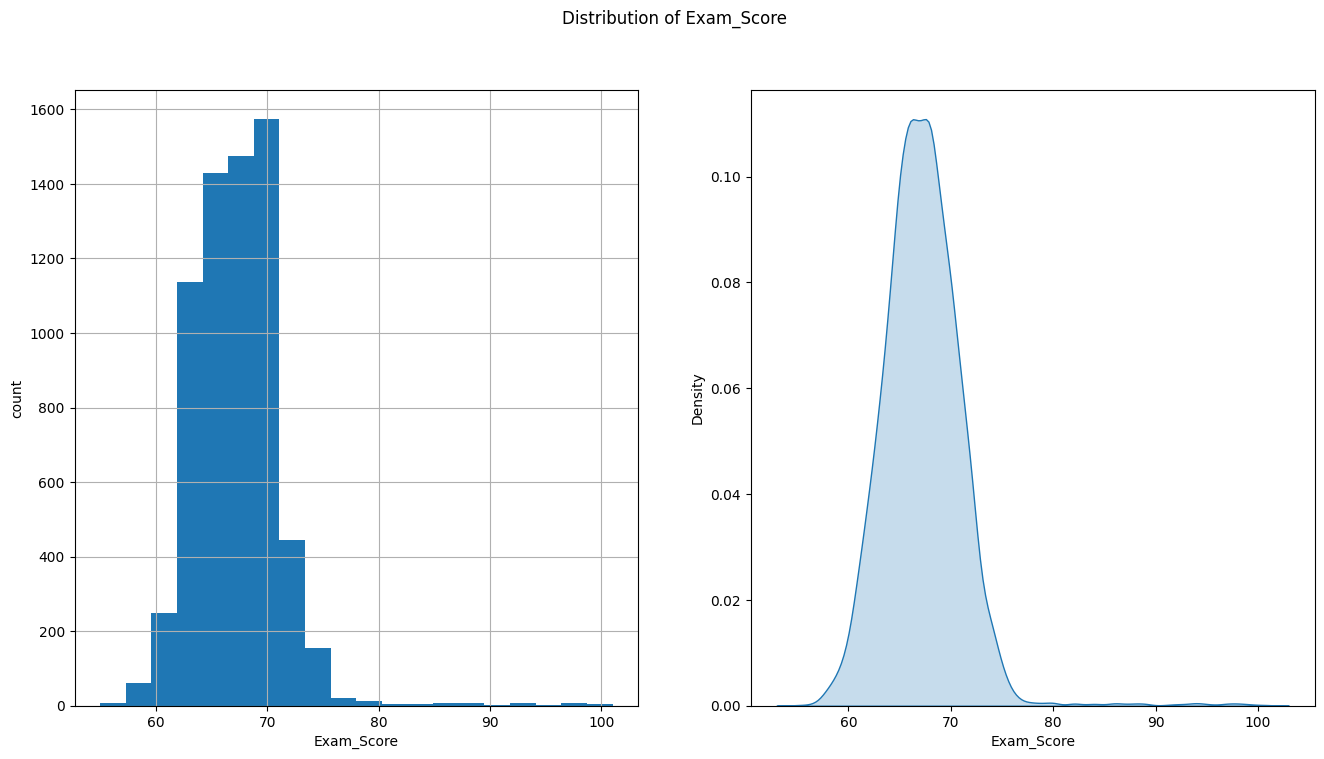

In [4]:
plt.figure(figsize = (16, 8))

plt.subplot(121)
df['Exam_Score'].hist(density=False, bins=20)
plt.ylabel('count')
plt.xlabel('Exam_Score')

plt.subplot(122)
sns.kdeplot(df['Exam_Score'], fill=True, legend=False)
plt.xlabel('Exam_Score')

plt.suptitle('Distribution of Exam_Score')
plt.show()

**Шаг 2. Получение основной информации о наборе данных.**

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6607 entries, 0 to 6606
Data columns (total 20 columns):
 #   Column                      Non-Null Count  Dtype 
---  ------                      --------------  ----- 
 0   Hours_Studied               6607 non-null   int64 
 1   Attendance                  6607 non-null   int64 
 2   Parental_Involvement        6607 non-null   object
 3   Access_to_Resources         6607 non-null   object
 4   Extracurricular_Activities  6607 non-null   object
 5   Sleep_Hours                 6607 non-null   int64 
 6   Previous_Scores             6607 non-null   int64 
 7   Motivation_Level            6607 non-null   object
 8   Internet_Access             6607 non-null   object
 9   Tutoring_Sessions           6607 non-null   int64 
 10  Family_Income               6607 non-null   object
 11  Teacher_Quality             6529 non-null   object
 12  School_Type                 6607 non-null   object
 13  Peer_Influence              6607 non-null   obje

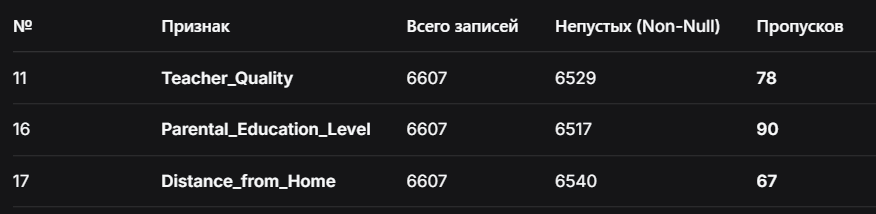

In [6]:
df.describe()

,Hours_Studied,Attendance,Sleep_Hours,Previous_Scores,Tutoring_Sessions,Physical_Activity,Exam_Score
count,6607.000000,6607.000000,6607.00000,6607.000000,6607.000000,6607.000000,6607.000000
mean,19.975329,79.977448,7.02906,75.070531,1.493719,2.967610,67.235659
std,5.990594,11.547475,1.46812,14.399784,1.230570,1.031231,3.890456
min,1.000000,60.000000,4.00000,50.000000,0.000000,0.000000,55.000000
25%,16.000000,70.000000,6.00000,63.000000,1.000000,2.000000,65.000000
50%,20.000000,80.000000,7.00000,75.000000,1.000000,3.000000,67.000000
75%,24.000000,90.000000,8.00000,88.000000,2.000000,4.000000,69.000000
max,44.000000,100.000000,10.00000,100.000000,8.000000,6.000000,101.000000


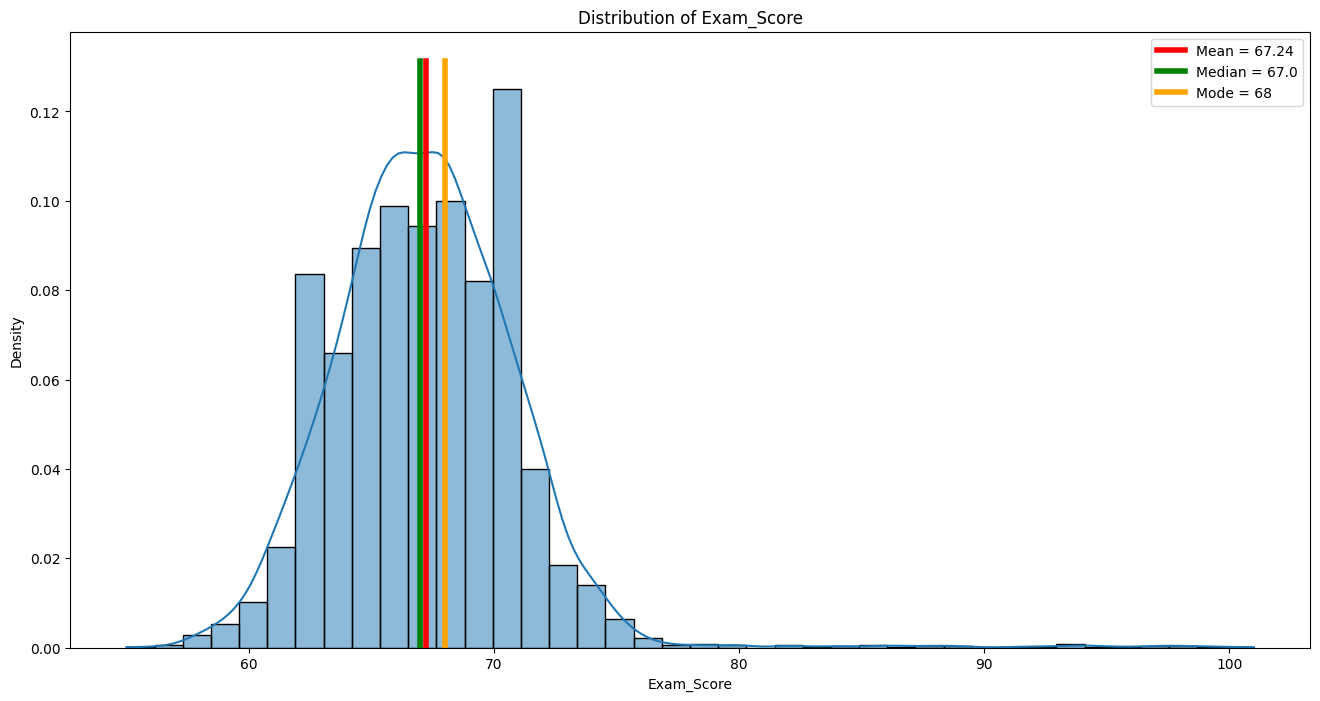

In [7]:
# Статистики
target_mean = round(df['Exam_Score'].mean(), 2)
target_median = df['Exam_Score'].median()
target_mode = df['Exam_Score'].mode()[0]

# График
plt.figure(figsize=(16, 8))

sns.histplot(df['Exam_Score'], bins=40, kde=True, stat='density')

# Берём реальный максимум по оси Y
ymax = plt.ylim()[1]
y = np.linspace(0, ymax, 10)

plt.plot([target_mean] * 10, y, label=f'Mean = {target_mean}', linewidth=4, color='red')
plt.plot([target_median] * 10, y, label=f'Median = {target_median}', linewidth=4, color='green')
plt.plot([target_mode] * 10, y, label=f'Mode = {target_mode}', linewidth=4, color='orange')

plt.title('Distribution of Exam_Score')
plt.legend()
plt.show()

**Шаг 3. Анализ числовых признаков. Заполнение пропусков и устранение аномалий.**

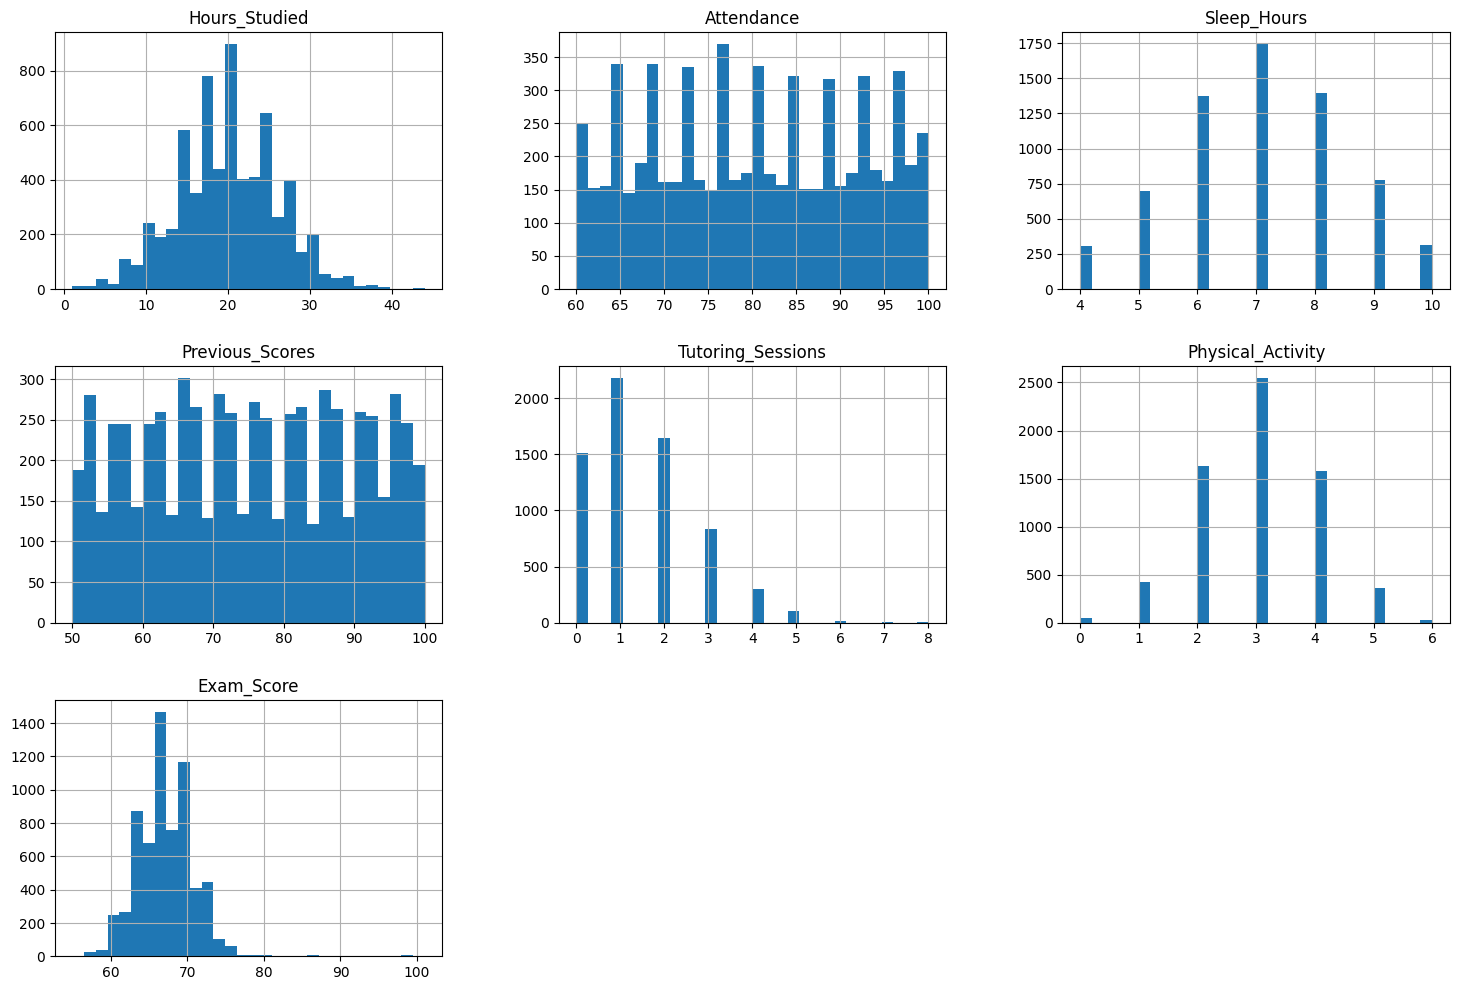

In [8]:
digital_features=df.select_dtypes(exclude=['object'])
digital_features.hist(figsize=(18,12), bins=30)
plt.show()

**Пропуски**

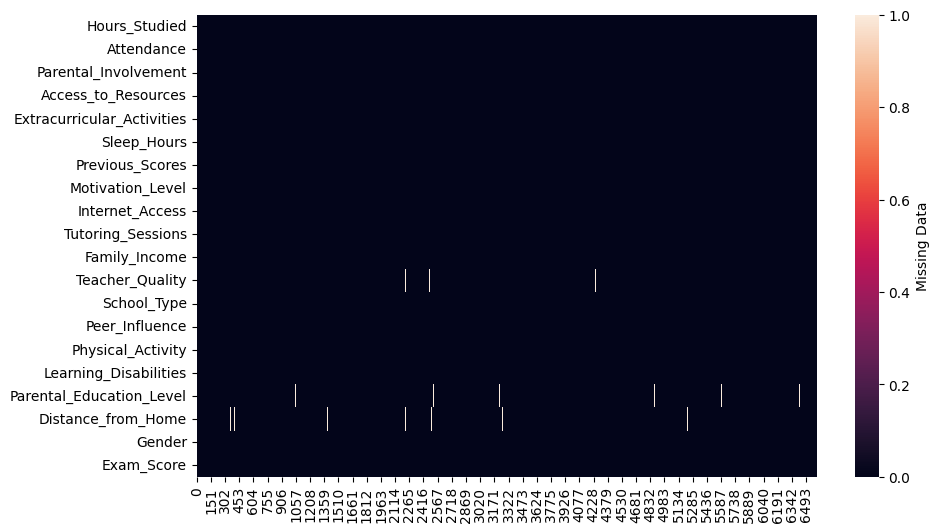

In [9]:
plt.figure(figsize=(10,6))
sns.heatmap(df.isna().transpose(),
            cbar_kws={'label': 'Missing Data'});

**Аномалии**

In [10]:
df['Exam_Score'].value_counts()

,count
Exam_Score,
68,759
66,751
67,717
65,679
69,624
70,542
64,501
71,408
63,371


In [11]:
df.loc[df['Exam_Score'].isin([101]), 'Exam_Score'] = 100

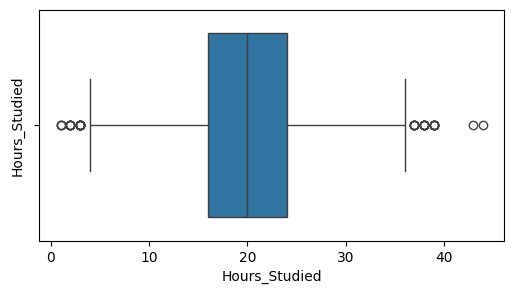

In [12]:
plt.figure(figsize=(6, 3))

sns.boxplot(x=df['Hours_Studied'], whis=1.5)

plt.ylabel('Hours_Studied')
plt.show()

In [13]:
df.loc[(df['Hours_Studied'] > 37) | ((df['Hours_Studied'] < 4)), 'Hours_Studied'] =  df['Hours_Studied'].median()

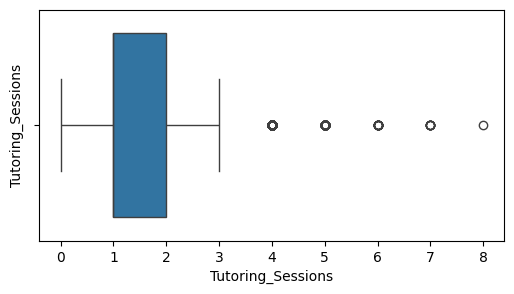

In [14]:
plt.figure(figsize=(6, 3))

sns.boxplot(x=df['Tutoring_Sessions'], whis=1.5)

plt.ylabel('Tutoring_Sessions')
plt.show()

In [15]:
df.loc[(df['Tutoring_Sessions'] > 3), 'Tutoring_Sessions'] =  df['Tutoring_Sessions'].median()

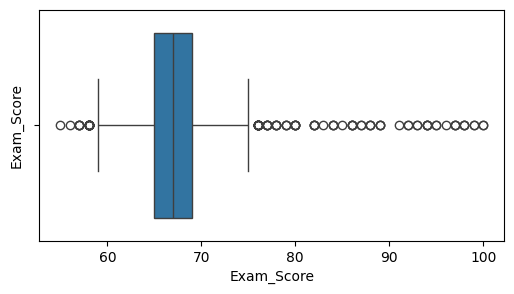

In [16]:
plt.figure(figsize=(6, 3))

sns.boxplot(x=df['Exam_Score'], whis=1.5)

plt.ylabel('Exam_Score')
plt.show()

In [17]:
df.loc[(df['Exam_Score'] > 80) | ((df['Exam_Score'] < 55)), 'Exam_Score'] =  df['Exam_Score'].median()

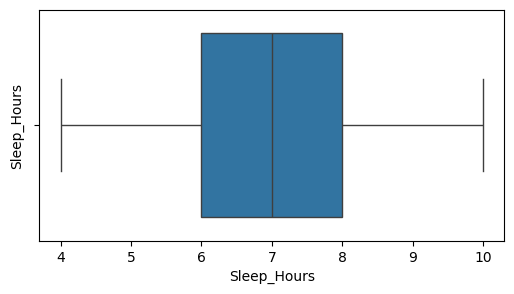

In [18]:
plt.figure(figsize=(6, 3))

sns.boxplot(x=df['Sleep_Hours'], whis=1.5)

plt.ylabel('Sleep_Hours')
plt.show()

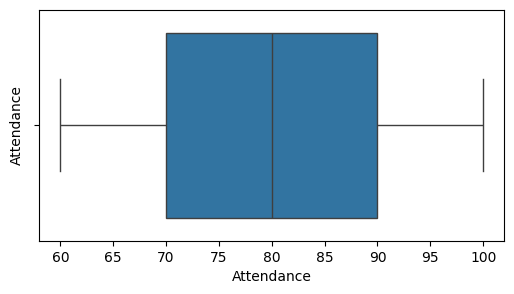

In [19]:
plt.figure(figsize=(6, 3))

sns.boxplot(x=df['Attendance'], whis=1.5)

plt.ylabel('Attendance')
plt.show()

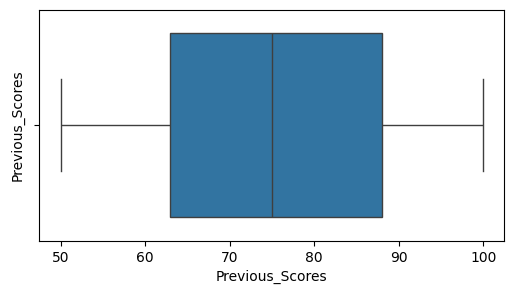

In [20]:
plt.figure(figsize=(6, 3))

sns.boxplot(x=df['Previous_Scores'], whis=1.5)

plt.ylabel('Previous_Scores')
plt.show()

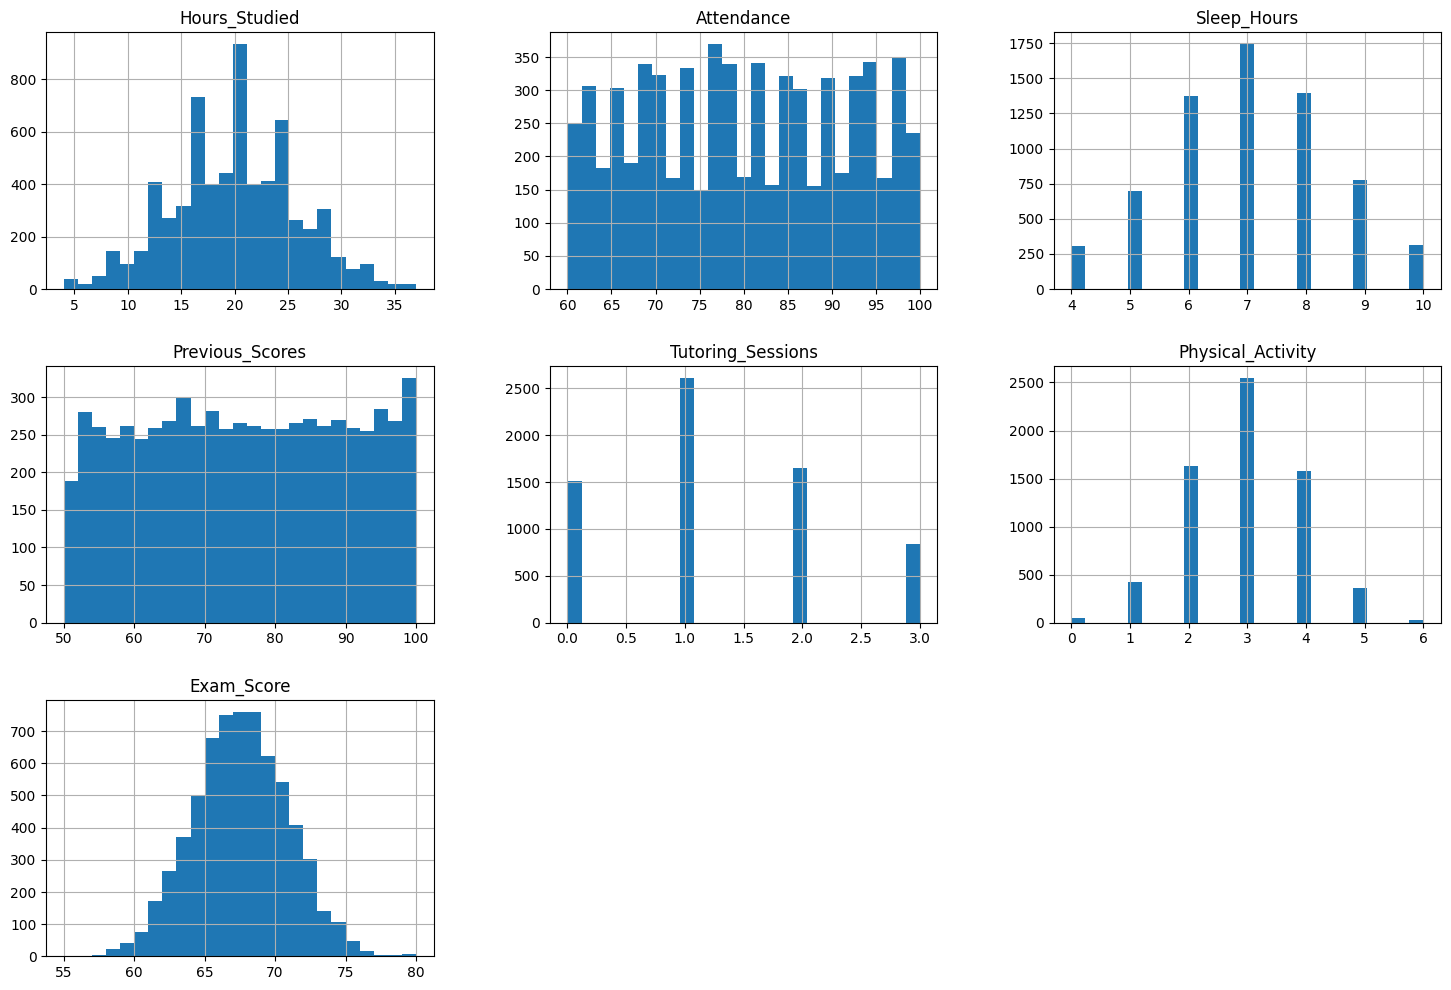

In [21]:
digital_features=df.select_dtypes(exclude=['object'])
digital_features.hist(figsize=(18,12), bins=25)
plt.show()

**Шаг 4. Анализ категориальных признаков. Заполнение пропусков и устранение аномалий**

In [22]:
df_obj_features = df.select_dtypes(include='object')
df_obj_features.head()

,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Motivation_Level,Internet_Access,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender
0,Low,High,No,Low,Yes,Low,Medium,Public,Positive,No,High School,Near,Male
1,Low,Medium,No,Low,Yes,Medium,Medium,Public,Negative,No,College,Moderate,Female
2,Medium,Medium,Yes,Medium,Yes,Medium,Medium,Public,Neutral,No,Postgraduate,Near,Male
3,Low,Medium,Yes,Medium,Yes,Medium,Medium,Public,Negative,No,High School,Moderate,Male
4,Medium,Medium,Yes,Medium,Yes,Medium,High,Public,Neutral,No,College,Near,Female


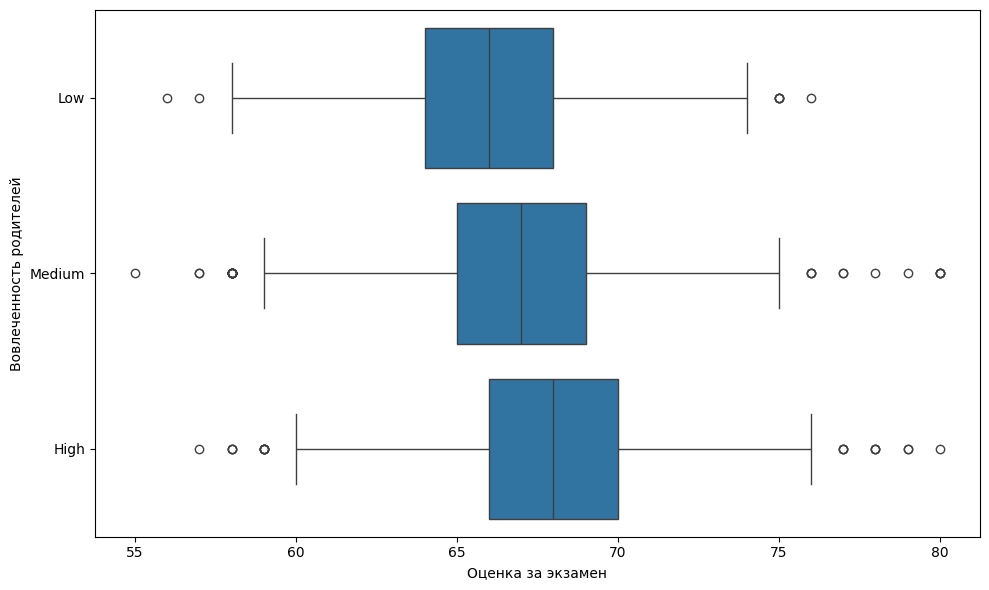

In [23]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x='Exam_Score',
    y='Parental_Involvement'
)

plt.xlabel('Оценка за экзамен')
plt.ylabel('Вовлеченность родителей')
plt.tight_layout()
plt.show()

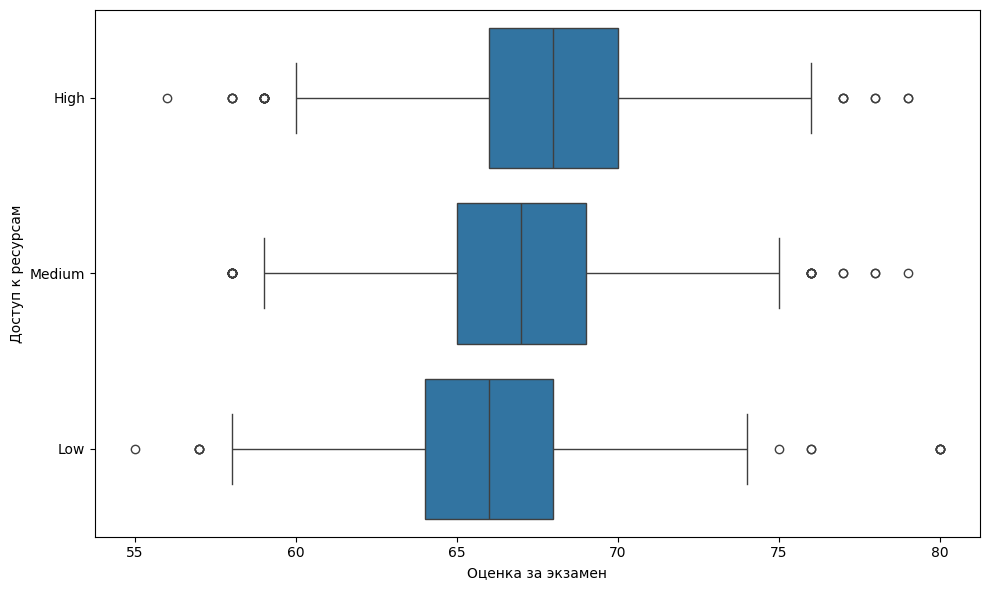

In [24]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x='Exam_Score',
    y='Access_to_Resources'
)

plt.xlabel('Оценка за экзамен')
plt.ylabel('Доступ к ресурсам')
plt.tight_layout()
plt.show()

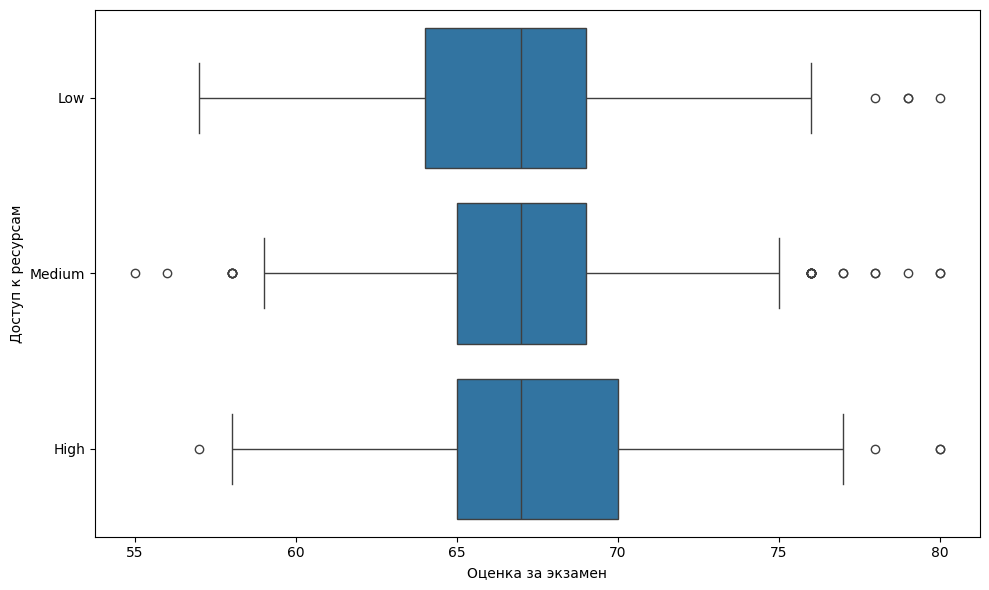

In [25]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x='Exam_Score',
    y='Motivation_Level'
)

plt.xlabel('Оценка за экзамен')
plt.ylabel('Доступ к ресурсам')
plt.tight_layout()
plt.show()

**Заполнение пропусков модой**

In [26]:
for col in ['Teacher_Quality', 'Parental_Education_Level', 'Distance_from_Home']:
    df[col] = df[col].fillna(df[col].mode()[0])

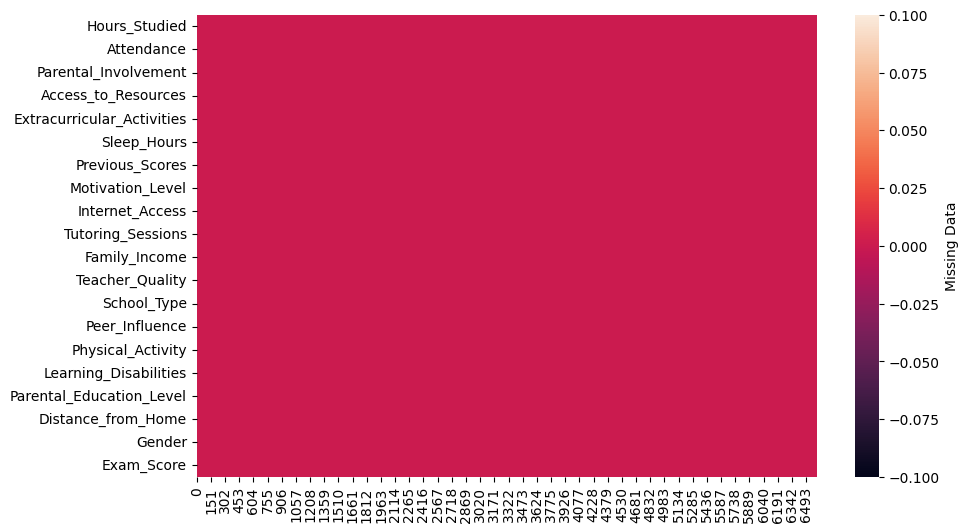

In [27]:
plt.figure(figsize=(10,6))
sns.heatmap(df.isna().transpose(),
            cbar_kws={'label': 'Missing Data'});

In [28]:
print(df.isna().sum())

Hours_Studied                 0
Attendance                    0
Parental_Involvement          0
Access_to_Resources           0
Extracurricular_Activities    0
Sleep_Hours                   0
Previous_Scores               0
Motivation_Level              0
Internet_Access               0
Tutoring_Sessions             0
Family_Income                 0
Teacher_Quality               0
School_Type                   0
Peer_Influence                0
Physical_Activity             0
Learning_Disabilities         0
Parental_Education_Level      0
Distance_from_Home            0
Gender                        0
Exam_Score                    0
dtype: int64


**Шаг 5. Кодирование переменных.**

Большинство алгоритмов машинного обучения работают только с числами, поэтому категориальные признаки нужно закодировать. Метод выбирается по типу признака (см. описание признаков выше):

- **порядковые** признаки (Low < Medium < High и т.п.) — порядковое кодирование (Ordinal / Label Encoding) с сохранением порядка: 0, 1, 2;
- **бинарные** признаки (Yes/No) — бинаризация: 1 и 0;
- **номинальные** признаки без порядка (Peer_Influence, School_Type, Gender) — One-Hot Encoding.

In [29]:
# Копия данных, чтобы при необходимости можно было вернуться к исходному виду
df_raw = df.copy()

# 1. Порядковое кодирование: порядок категорий задаём явно
ordinal_maps = {
    'Parental_Involvement':     {'Low': 0, 'Medium': 1, 'High': 2},
    'Access_to_Resources':      {'Low': 0, 'Medium': 1, 'High': 2},
    'Motivation_Level':         {'Low': 0, 'Medium': 1, 'High': 2},
    'Family_Income':            {'Low': 0, 'Medium': 1, 'High': 2},
    'Teacher_Quality':          {'Low': 0, 'Medium': 1, 'High': 2},
    'Parental_Education_Level': {'High School': 0, 'College': 1, 'Postgraduate': 2},
    'Distance_from_Home':       {'Near': 0, 'Moderate': 1, 'Far': 2},
}
for col, mapping in ordinal_maps.items():
    df[col] = df[col].map(mapping)

df[list(ordinal_maps)].head()

,Parental_Involvement,Access_to_Resources,Motivation_Level,Family_Income,Teacher_Quality,Parental_Education_Level,Distance_from_Home
0,0,2,0,0,1,0,0
1,0,1,0,1,1,1,1
2,1,1,1,1,1,2,0
3,0,1,1,1,1,0,1
4,1,1,1,1,2,1,0


In [30]:
# 2. Бинаризация признаков Yes / No -> 1 / 0
binary_cols = ['Extracurricular_Activities', 'Internet_Access', 'Learning_Disabilities']
for col in binary_cols:
    df[col] = df[col].map({'Yes': 1, 'No': 0})

df[binary_cols].head()

,Extracurricular_Activities,Internet_Access,Learning_Disabilities
0,0,1,0
1,0,1,0
2,1,1,0
3,1,1,0
4,1,1,0


In [31]:
# 3. One-Hot Encoding для номинальных признаков.
# drop_first=True убирает одну из категорий, чтобы не создавать линейно зависимые столбцы
# (для бинарных School_Type и Gender остаётся один столбец, для Peer_Influence - два).
ohe_cols = ['Peer_Influence', 'School_Type', 'Gender']
df = pd.get_dummies(df, columns=ohe_cols, drop_first=True, dtype=int)

df.filter(like='Peer_Influence').join(df.filter(like='School_Type')).join(df.filter(like='Gender')).head()

,Peer_Influence_Neutral,Peer_Influence_Positive,School_Type_Public,Gender_Male
0,0,1,1,1
1,0,0,1,0
2,1,0,1,1
3,0,0,1,1
4,1,0,1,0


In [32]:
# Проверка: все признаки должны стать числовыми, пропусков быть не должно
print('Признаков:', df.shape[1])
print('Нечисловые столбцы:', df.select_dtypes(exclude='number').columns.tolist())
print('Пропусков:', df.isna().sum().sum())
df.head()

Признаков: 21
Нечисловые столбцы: []
Пропусков: 0


,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,...,Teacher_Quality,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Exam_Score,Peer_Influence_Neutral,Peer_Influence_Positive,School_Type_Public,Gender_Male
0,23,84,0,2,0,7,73,0,1,0,...,1,3,0,0,0,67,0,1,1,1
1,19,64,0,1,0,8,59,0,1,2,...,1,4,0,1,1,61,0,0,1,0
2,24,98,1,1,1,7,91,1,1,2,...,1,4,0,2,0,74,1,0,1,1
3,29,89,0,1,1,8,98,1,1,1,...,1,4,0,0,1,71,0,0,1,1
4,19,92,1,1,1,6,65,1,1,3,...,2,4,0,1,0,70,1,0,1,0


**Шаг 6. Генерация новых признаков.**

Создаются признаки разных типов: комбинация существующих признаков, дискретизация, бинаризация и агрегация.

In [33]:
# 1. Комбинация признаков: «эффективные» часы подготовки = часы подготовки * доля посещённых занятий
df['Effective_Study_Hours'] = round(df['Hours_Studied'] * df['Attendance'] / 100, 2)

# 2. Комбинация признаков: индекс поддержки студента - сумма порядковых оценок
#    вовлечённости родителей, доступа к ресурсам, качества преподавателей и дохода семьи (значения 0..8)
df['Support_Index'] = (df['Parental_Involvement'] + df['Access_to_Resources']
                       + df['Teacher_Quality'] + df['Family_Income'])

# 3. Дискретизация: нагрузка по часам подготовки в неделю (0 - низкая, 1 - средняя, 2 - высокая, 3 - очень высокая)
df['Study_Load_Cat'] = pd.cut(df['Hours_Studied'],
                              bins=[0, 15, 20, 25, np.inf],
                              labels=[0, 1, 2, 3]).astype(int)

# 4. Бинаризация: высокая посещаемость (>= 85%) - 1, иначе - 0
df['High_Attendance'] = (df['Attendance'] >= 85).astype(int)

# 5. Агрегация: отклонение часов подготовки студента от среднего по группе с тем же уровнем мотивации
df['Hours_vs_Motivation_mean'] = round(
    df['Hours_Studied'] - df.groupby('Motivation_Level')['Hours_Studied'].transform('mean'), 2)

new_features = ['Effective_Study_Hours', 'Support_Index', 'Study_Load_Cat',
                'High_Attendance', 'Hours_vs_Motivation_mean']
df[new_features].head()

,Effective_Study_Hours,Support_Index,Study_Load_Cat,High_Attendance,Hours_vs_Motivation_mean
0,19.32,3,2,0,3.02
1,12.16,3,1,0,-0.98
2,23.52,4,2,1,3.90
3,25.81,3,3,1,8.90
4,17.48,5,1,1,-1.10


In [34]:
# Насколько новые признаки связаны с целевой переменной (корреляция Пирсона)
df[new_features + ['Exam_Score']].corr()['Exam_Score'].drop('Exam_Score').sort_values(ascending=False)

,Exam_Score
Effective_Study_Hours,0.739446
High_Attendance,0.567215
Hours_vs_Motivation_mean,0.499835
Study_Load_Cat,0.472212
Support_Index,0.278469


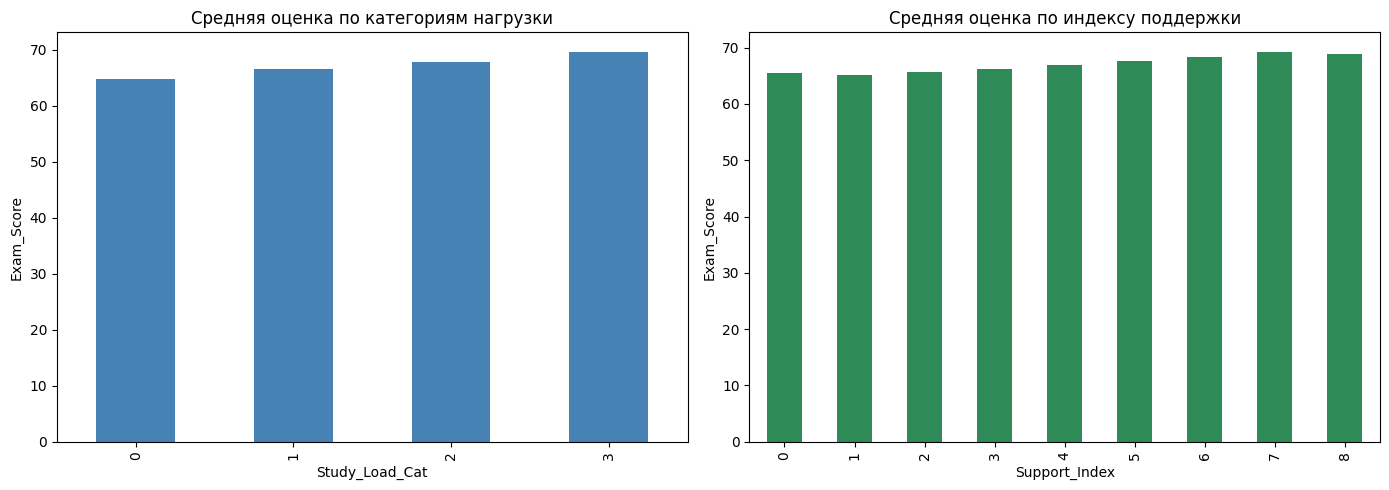

In [35]:
# Средняя оценка по категориям нагрузки и по индексу поддержки
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

df.groupby('Study_Load_Cat')['Exam_Score'].mean().plot(kind='bar', ax=axes[0], color='steelblue')
axes[0].set_title('Средняя оценка по категориям нагрузки')
axes[0].set_xlabel('Study_Load_Cat')
axes[0].set_ylabel('Exam_Score')

df.groupby('Support_Index')['Exam_Score'].mean().plot(kind='bar', ax=axes[1], color='seagreen')
axes[1].set_title('Средняя оценка по индексу поддержки')
axes[1].set_xlabel('Support_Index')
axes[1].set_ylabel('Exam_Score')

plt.tight_layout()
plt.show()

**Шаг 7. Стандартизация и нормализация данных.**

Признаки измеряются в разных единицах и диапазонах (посещаемость 60–100, сон 4–10 часов, количество сессий 0–3), а многие алгоритмы (линейные модели, kNN, SVM, нейронные сети) чувствительны к масштабу.

- **Стандартизация** (`StandardScaler`): $z = (x - \mu) / \sigma$. Среднее становится равным 0, стандартное отклонение — 1.
- **Нормализация** (`MinMaxScaler`): $x' = (x - x_{min}) / (x_{max} - x_{min})$. Значения приводятся к диапазону [0, 1].

Масштабируются только непрерывные и дискретные числовые признаки. Бинарные, One-Hot и порядковые признаки, а также целевая переменная `Exam_Score` не масштабируются.

In [36]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler

num_cols = ['Hours_Studied', 'Attendance', 'Sleep_Hours', 'Previous_Scores',
            'Tutoring_Sessions', 'Physical_Activity',
            'Effective_Study_Hours', 'Hours_vs_Motivation_mean']

# Статистики до масштабирования
df[num_cols].describe().loc[['mean', 'std', 'min', 'max']].round(2)

,Hours_Studied,Attendance,Sleep_Hours,Previous_Scores,Tutoring_Sessions,Physical_Activity,Effective_Study_Hours,Hours_vs_Motivation_mean
mean,19.98,79.98,7.03,75.07,1.27,2.97,15.98,-0.00
std,5.83,11.55,1.47,14.40,0.95,1.03,5.22,5.83
min,4.00,60.00,4.00,50.00,0.00,0.00,2.40,-16.10
max,37.00,100.00,10.00,100.00,3.00,6.00,35.52,17.29


In [37]:
# Стандартизация: среднее = 0, std = 1
df_std = df.copy()
df_std[num_cols] = StandardScaler().fit_transform(df[num_cols])

df_std[num_cols].describe().loc[['mean', 'std', 'min', 'max']].round(2)

,Hours_Studied,Attendance,Sleep_Hours,Previous_Scores,Tutoring_Sessions,Physical_Activity,Effective_Study_Hours,Hours_vs_Motivation_mean
mean,-0.00,-0.00,-0.00,0.00,0.00,-0.00,0.00,0.00
std,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00
min,-2.74,-1.73,-2.06,-1.74,-1.34,-2.88,-2.60,-2.76
max,2.92,1.73,2.02,1.73,1.81,2.94,3.75,2.97


In [38]:
# Нормализация: диапазон [0, 1]
df_norm = df.copy()
df_norm[num_cols] = MinMaxScaler().fit_transform(df[num_cols])

df_norm[num_cols].describe().loc[['mean', 'std', 'min', 'max']].round(2)

,Hours_Studied,Attendance,Sleep_Hours,Previous_Scores,Tutoring_Sessions,Physical_Activity,Effective_Study_Hours,Hours_vs_Motivation_mean
mean,0.48,0.50,0.50,0.50,0.42,0.49,0.41,0.48
std,0.18,0.29,0.24,0.29,0.32,0.17,0.16,0.17
min,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
max,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00


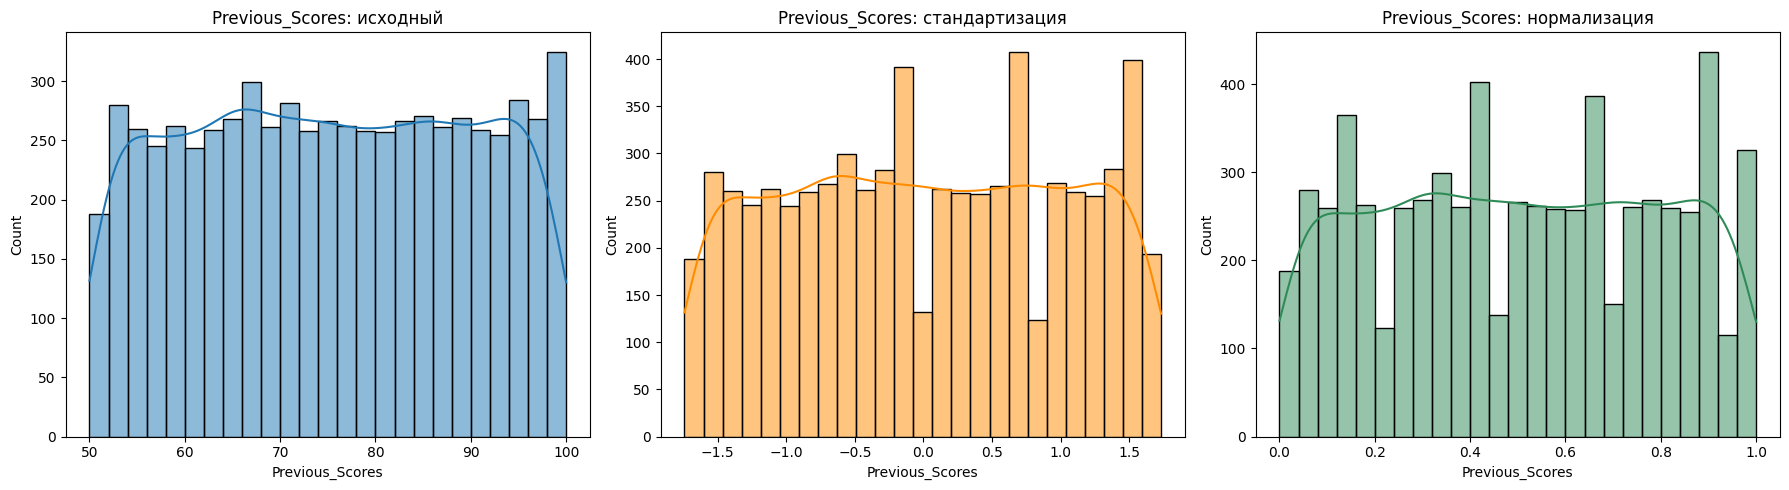

In [39]:
# Сравнение распределений признака до и после масштабирования
feature = 'Previous_Scores'

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.histplot(df[feature], bins=25, kde=True, ax=axes[0])
axes[0].set_title(f'{feature}: исходный')

sns.histplot(df_std[feature], bins=25, kde=True, ax=axes[1], color='darkorange')
axes[1].set_title(f'{feature}: стандартизация')

sns.histplot(df_norm[feature], bins=25, kde=True, ax=axes[2], color='seagreen')
axes[2].set_title(f'{feature}: нормализация')

plt.tight_layout()
plt.show()

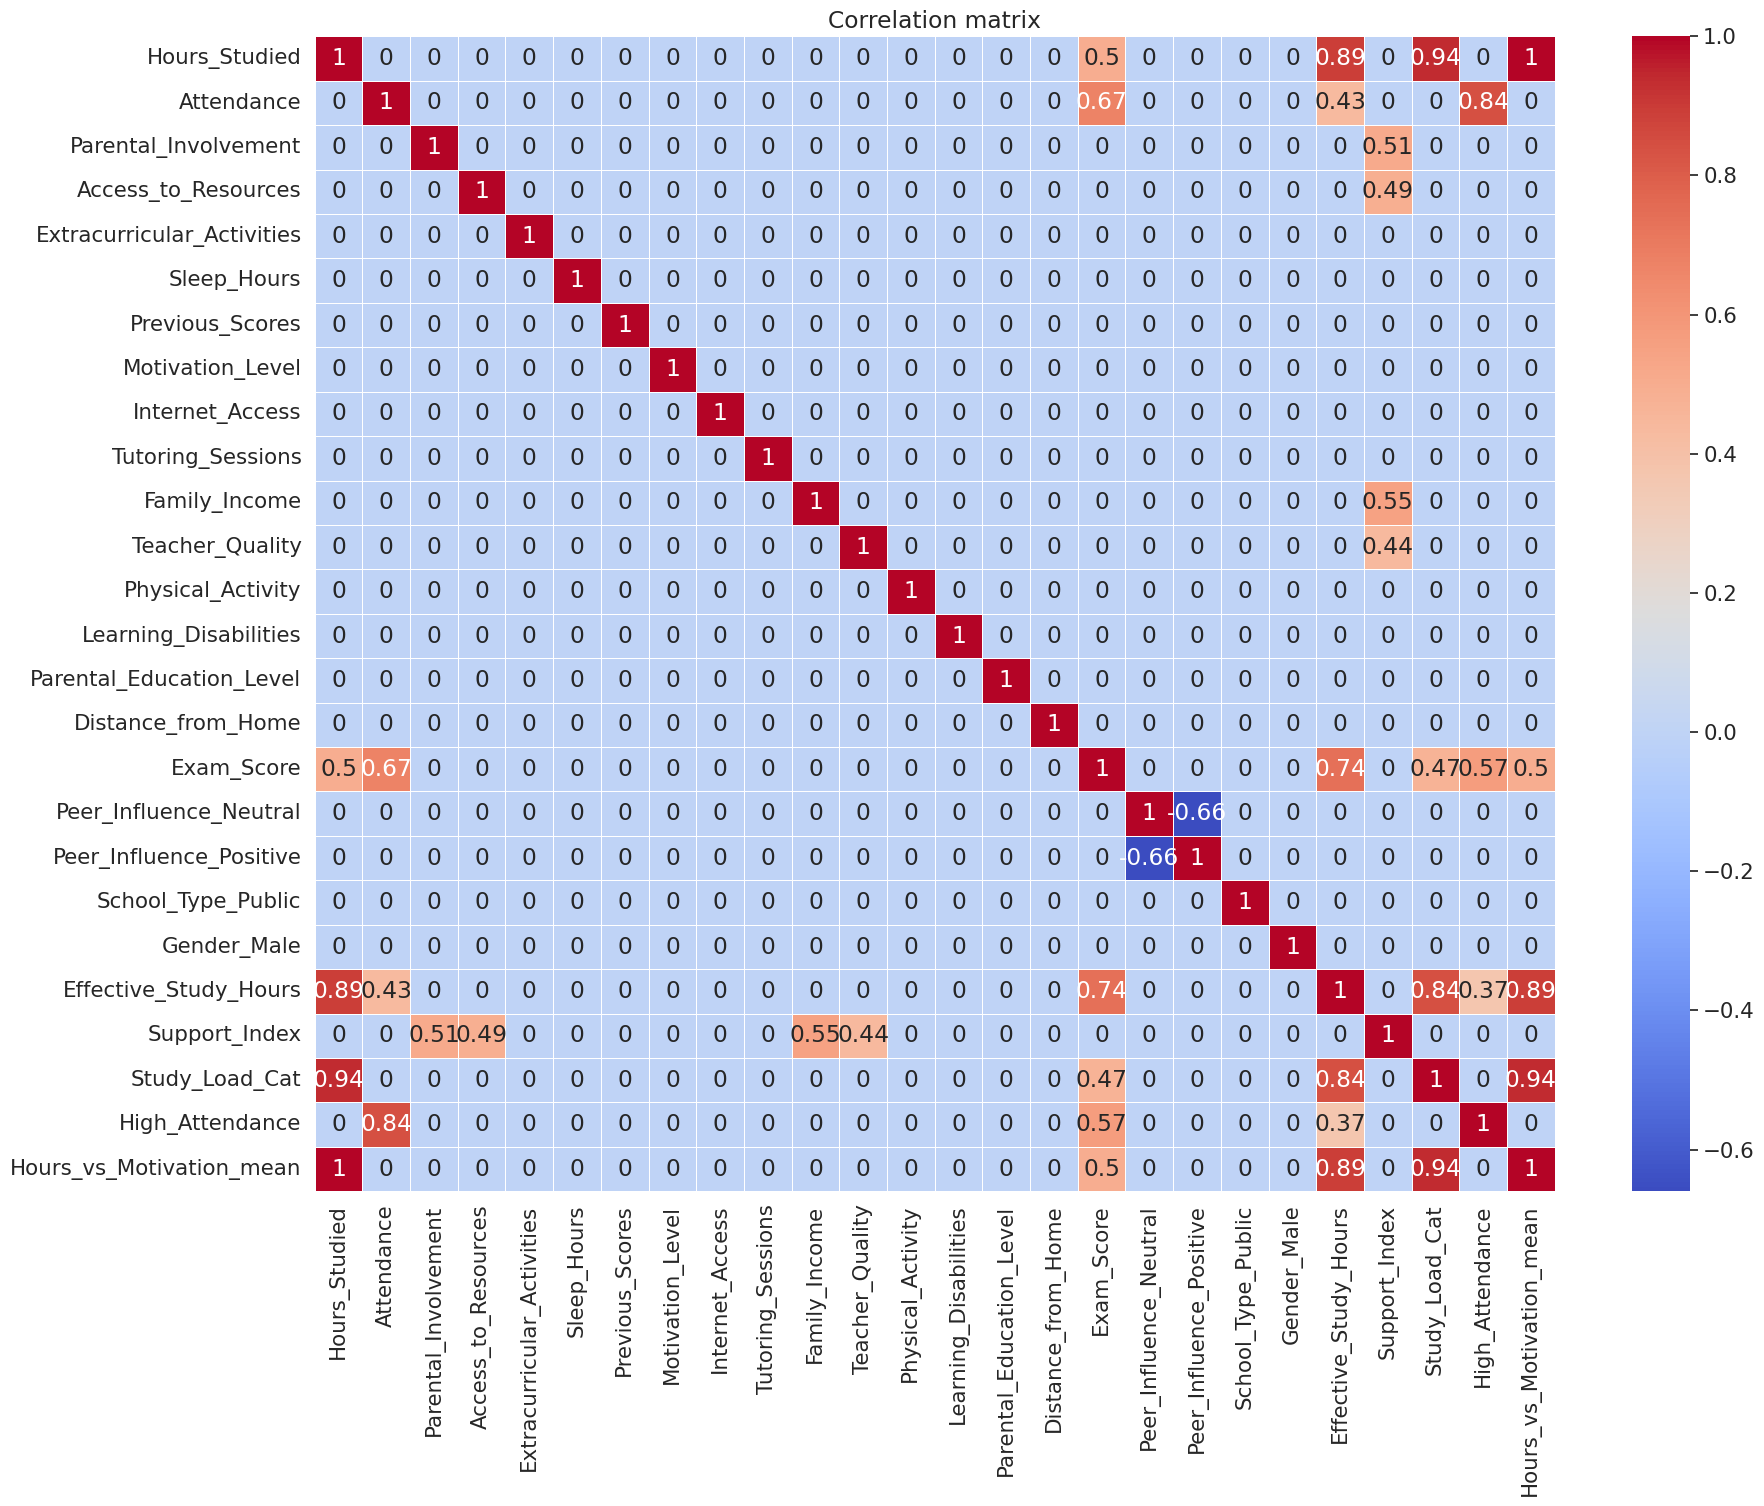

In [43]:
plt.figure(figsize=(20, 15))

sns.set(font_scale=1.4)

corr_matrix = df.corr()
corr_matrix = np.round(corr_matrix, 2)
corr_matrix[np.abs(corr_matrix) < 0.3] = 0

sns.heatmap(corr_matrix, annot=True, linewidths=.5, cmap='coolwarm')

plt.title('Correlation matrix')
plt.show()

**Вывод.** Форма распределения при масштабировании не меняется — меняются только шкала и положение. После стандартизации все масштабируемые признаки имеют среднее 0 и стандартное отклонение 1, после нормализации — значения в диапазоне [0, 1]. Признаки приведены к единой шкале, поэтому набор можно использовать для моделей, чувствительных к масштабу. Бинарные, One-Hot и порядковые признаки, а также целевая переменная остались без изменений.

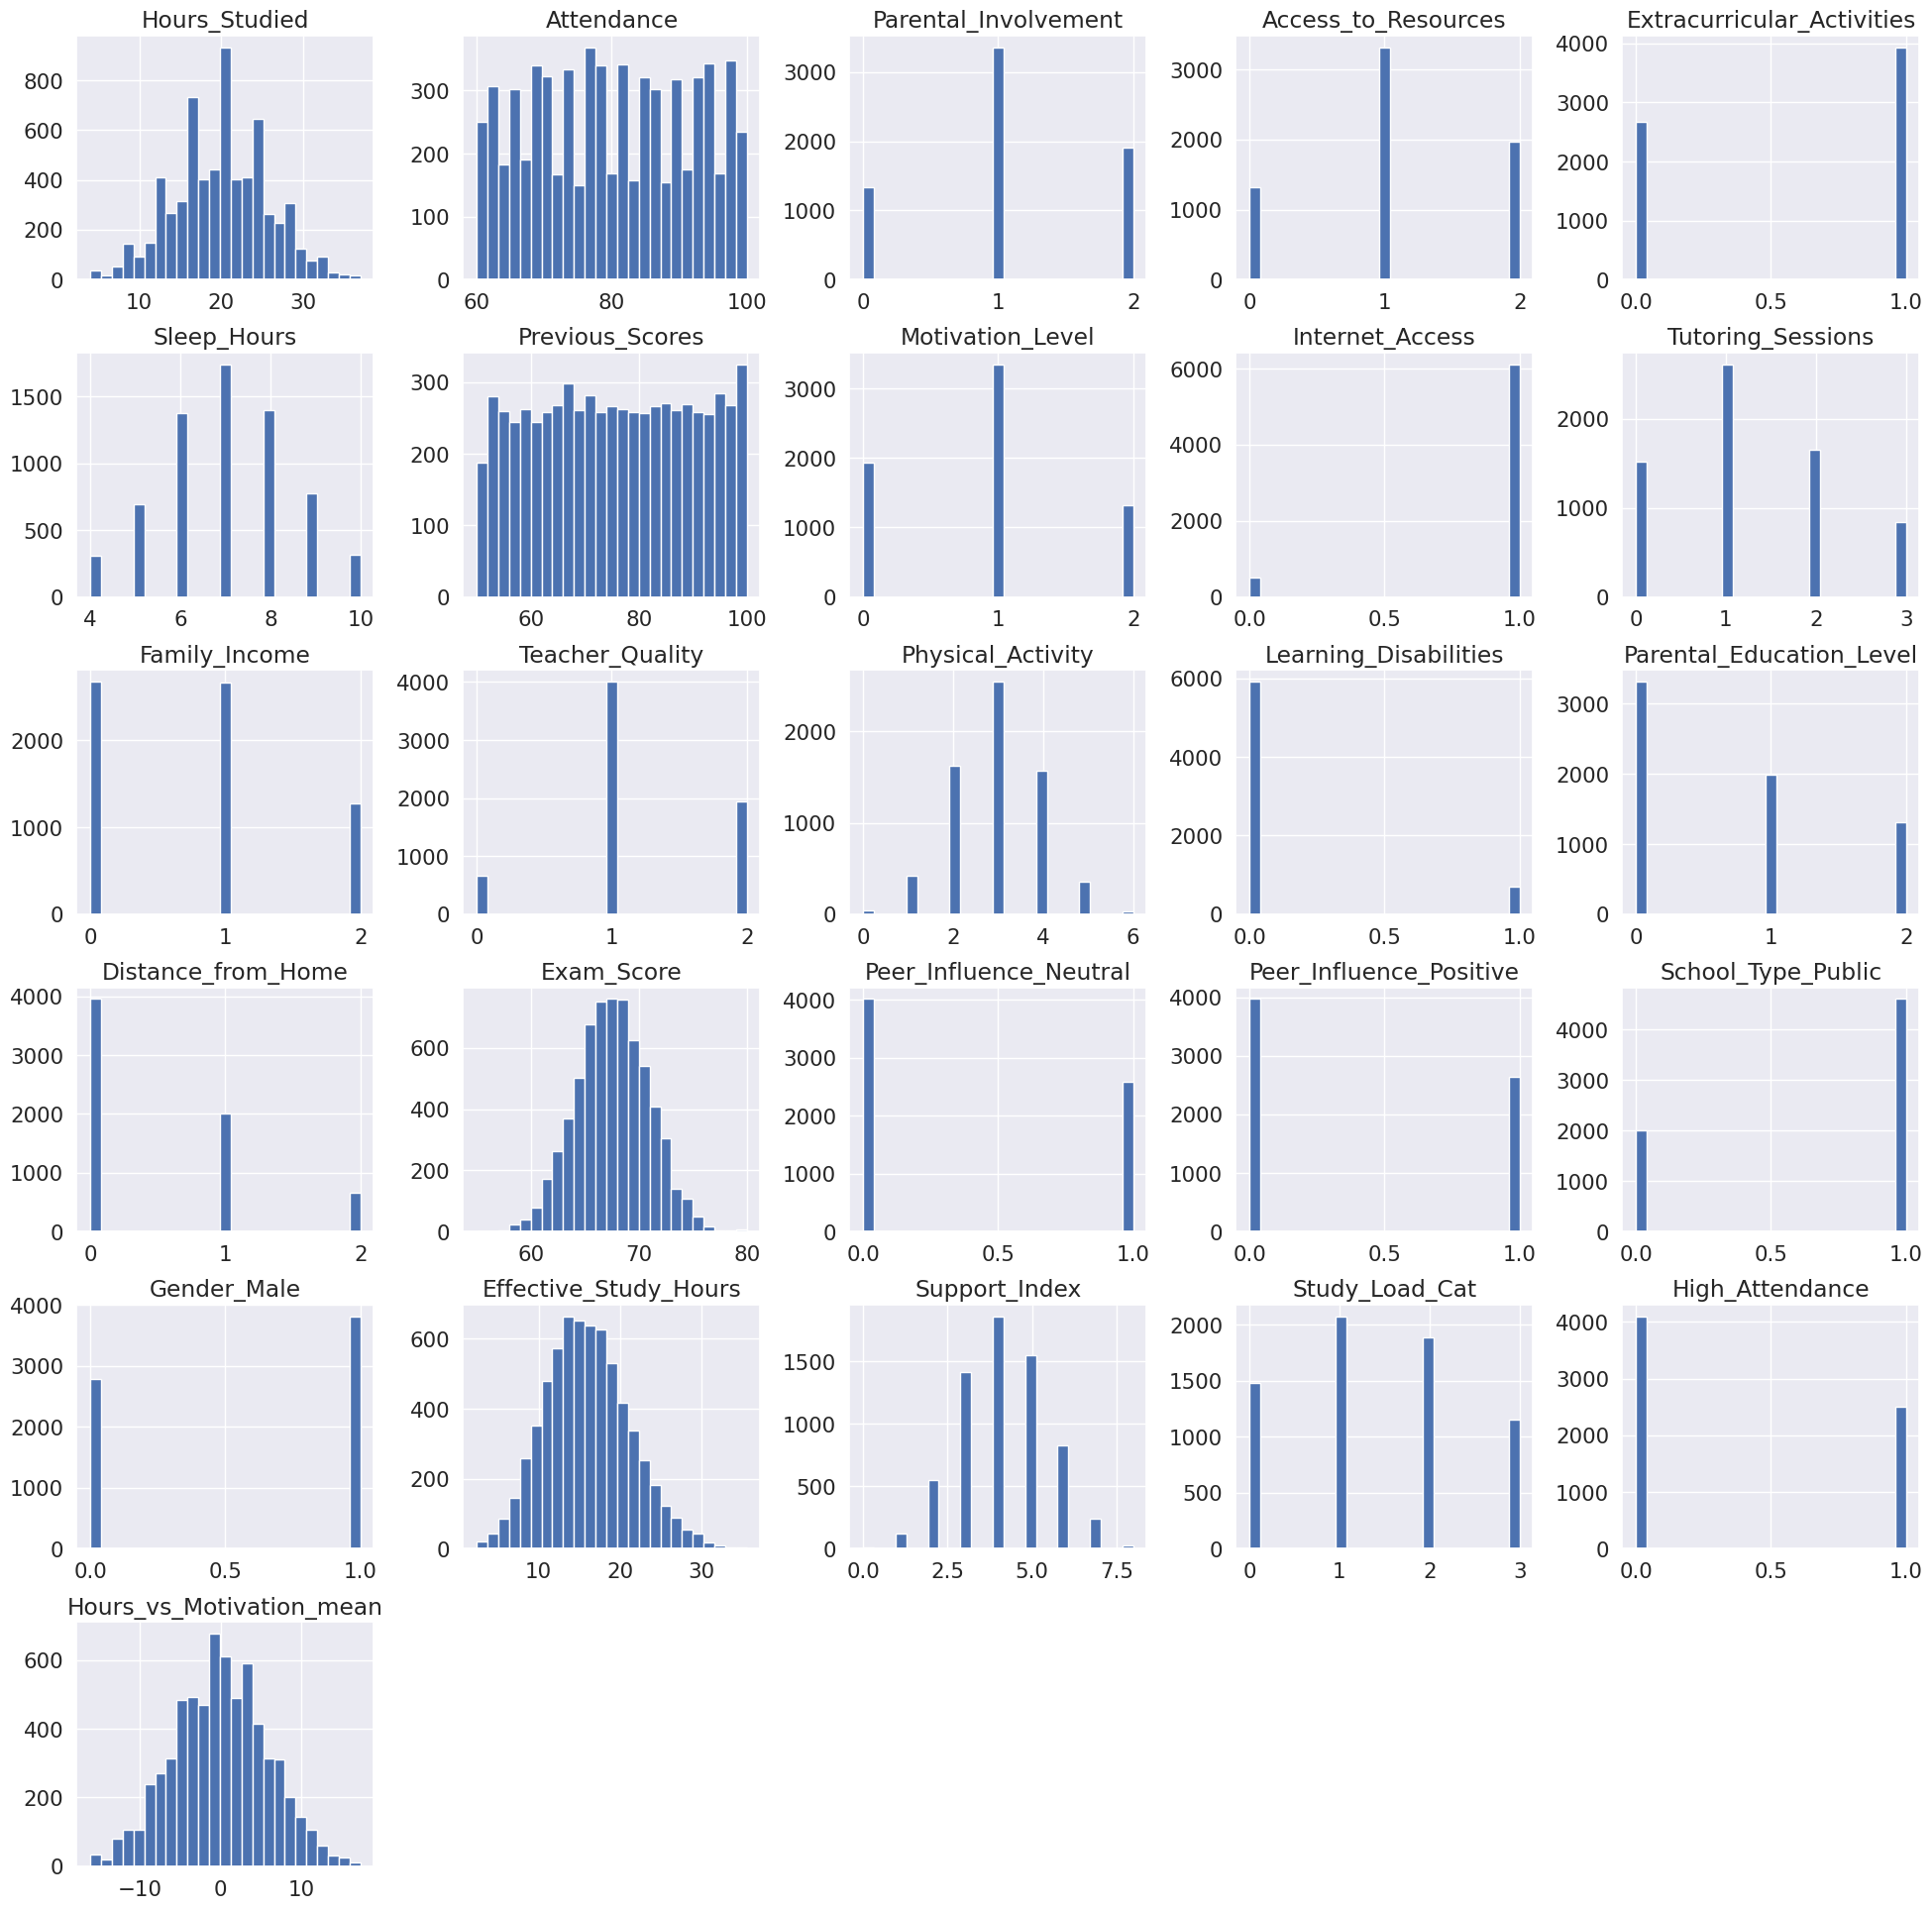

In [46]:
digital_features=df.select_dtypes(exclude=['object'])
digital_features.hist(figsize=(24,24), bins=25)
plt.show()

**Шаг 8. Сохранение очищенного набора данных.**

In [42]:
path = '/content/drive/MyDrive/'

df.to_csv(path + 'cleaned_data.csv', index=False)                     # очищенный, закодированный, с новыми признаками
df_std.to_csv(path + 'cleaned_data_standardized.csv', index=False)    # + стандартизация
df_norm.to_csv(path + 'cleaned_data_normalized.csv', index=False)     # + нормализация

print('Сохранено:', df.shape, df_std.shape, df_norm.shape)

Сохранено: (6607, 26) (6607, 26) (6607, 26)
